In [24]:
%pip install numpy matplotlib opencv-python pillow rawpy

   ---------------------------------------- 0.0/949.4 kB ? eta -:--:--
   ---------------------------------------- 949.4/949.4 kB 17.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import rawpy

In [47]:
def ShowImage(image, title='Image', cmap_type=None):
    plt.imshow(image, cmap=cmap_type)
    plt.title(title)
    plt.axis('off')
    plt.show()

In [9]:
from matplotlib import colors

def ShowRGB(image, title='3D Scatter Plot'):
    # Get the dimensions of the image
    height, width, channels = image.shape
    # Flatten the arrays for plotting
    r, g, b = cv2.split(image)
    pixel_colors = image.reshape((height * width, 3))
    norm = colors.Normalize(vmin=-1, vmax=1)
    norm.autoscale(pixel_colors)
    pixel_colors = norm(pixel_colors).tolist()

    # Create a 3D scatter plot
    fig = plt.figure(figsize=(10, 8))

    ax = fig.add_subplot(1, 1, 1, projection='3d')
    ax.scatter(r.flatten(), g.flatten(), b.flatten(), facecolors=pixel_colors, marker='.')
    
    ax.set_xlabel("Red")
    ax.set_ylabel("Green")
    ax.set_zlabel("Blue")
    ax.set_title(title)
    
    plt.show()

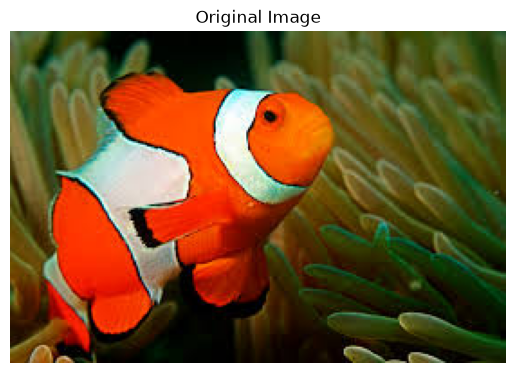

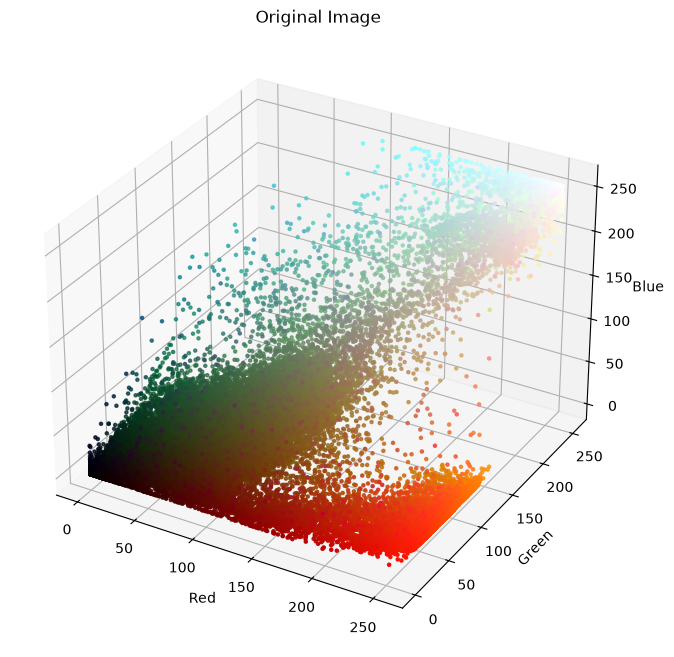

In [10]:
image = cv2.imread("images/nemo0.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
ShowImage(image, "Original Image")
ShowRGB(image, "Original Image")

In [11]:
# Convert the image to HSV color space
def ShowHSV(image, title='3D Scatter Plot in HSV'):
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    h, s, v = cv2.split(hsv_image)
    pixel_colors = image.reshape((image.shape[0] * image.shape[1], 3))
    norm = colors.Normalize(vmin=-1, vmax=1)
    norm.autoscale(pixel_colors)
    pixel_colors = norm(pixel_colors).tolist()

    # Create a 3D scatter plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    ax.scatter(h.flatten(), s.flatten(), v.flatten(), facecolors=pixel_colors, marker='.')
    
    ax.set_xlabel("Hue")
    ax.set_ylabel("Saturation")
    ax.set_zlabel("Value")
    ax.set_title(title)
    
    plt.show()

    return hsv_image

In [12]:
def HSVMask(hsv_image, hue_range, sat_range, value_range):
    # Create a mask based on the hue range
    lower_bound = np.array([hue_range[0], sat_range[0], value_range[0]])
    upper_bound = np.array([hue_range[1], sat_range[1], value_range[1]])
    mask = cv2.inRange(hsv_image, lower_bound, upper_bound)
    return mask

In [13]:
def CombineMasks(mask1, mask2):
    # Combine two masks using bitwise OR
    combined_mask = cv2.bitwise_or(mask1, mask2)
    return combined_mask

In [14]:
def ApplyMask(image, mask):
    # Apply the mask to the original image
    result = cv2.bitwise_and(image, image, mask=mask)
    return result

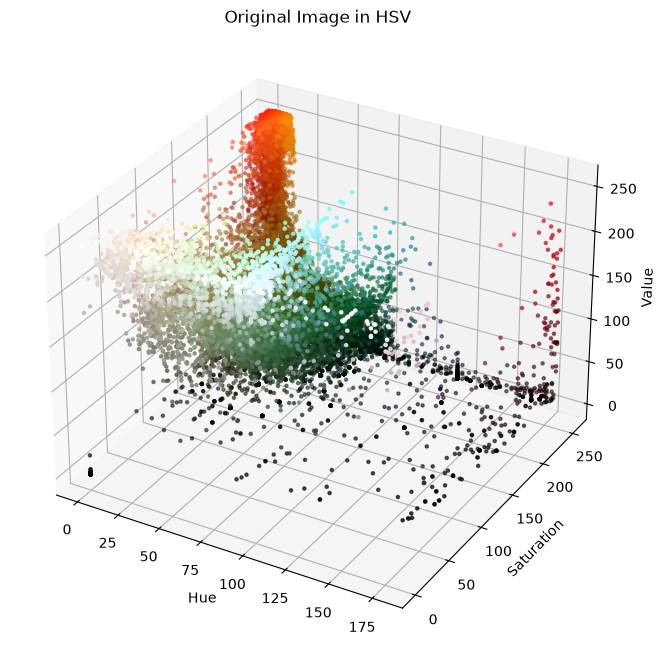

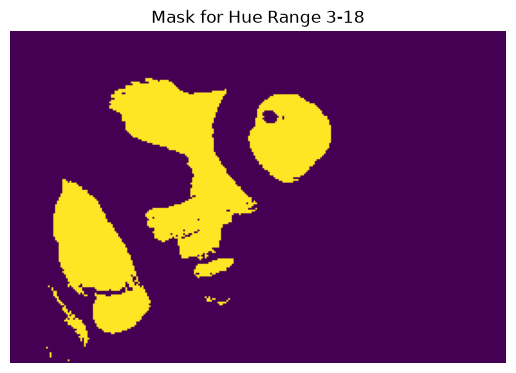

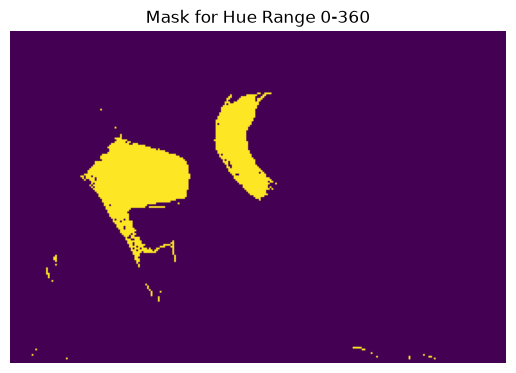

In [15]:
hsv_image = ShowHSV(image, "Original Image in HSV")

#red orange mask
hue_range = [3, 18]
value_range = [200, 255]
sat_range = [130, 255]
mask = HSVMask(hsv_image, hue_range, sat_range, value_range)
ShowImage(mask, "Mask for Hue Range {}-{}".format(hue_range[0], hue_range[1]))

# white mask
hue_range = [0, 360]
value_range = [180, 255]
sat_range = [0, 70]
mask2 = HSVMask(hsv_image, hue_range, sat_range, value_range)
ShowImage(mask2, "Mask for Hue Range {}-{}".format(hue_range[0], hue_range[1]))


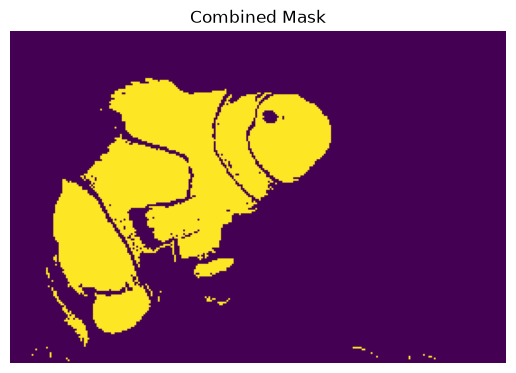

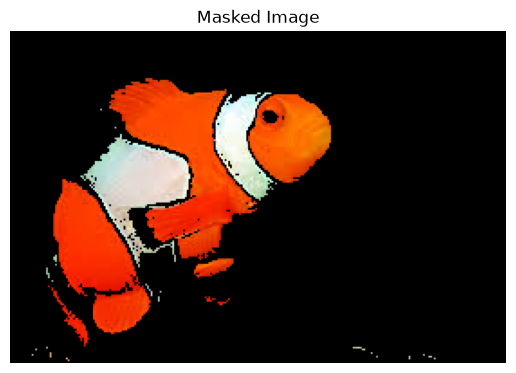

In [16]:
mask = CombineMasks(mask, mask2)
ShowImage(mask, "Combined Mask")
masked_image = ApplyMask(image, mask)
ShowImage(masked_image, "Masked Image")

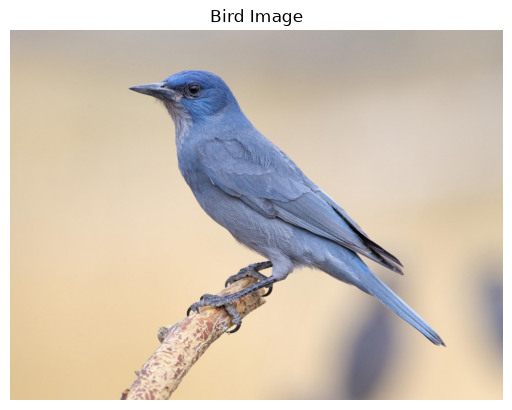

In [ ]:
bird = cv2.imread("images/bird.jpg")
bird = cv2.cvtColor(bird, cv2.COLOR_BGR2RGB)
ShowImage(bird, "Bird Image")

Un filtro de bayer es una estructura de filtros de color colocada sobre los sensores de camaras digitales. Dado que los sensores no tienen la capacidad de discernir colores, la luz incidente se filtra para ciertos valores de longitud de onda que corresponden a los colores rojo, verde y azul, y luego el valor recibido es cuantizado y almacenado. Como consecuencia, la imagen resultante es un arreglo bidimensional de valores que representan intensidad de luz, pero cada elemento se atribuye a un canal RGB segun la disposición de filtros utilizado. Dicha disposición depende de la cámara, y generalmente se busca una distribución que se asemeje a aquella encontrada en el ojo humano para lograr una mejor fidelidad.

El proceso de pasar de una imagen "raw" a una imagen con 3 canales se conoce como debayering o demosaicing, y consiste en conocer la distribución de los colores en la imagen en formato raw y utilizar esa información con alguna técnica de interpolación de color para construir un pixel RGB. Una técnica muy utilizada es realizar un promedio entre un punto y sus 8 vecinos. Conociendo a que canal corresponde cada valor es posible reconstruir los valores RGB del pixel de la imagen final.

A continuación se hizo una implementación del tutorial encontrado en el link:
https://cs.brown.edu/courses/cs129/2020_Fall/labs/lab_raw/index.html

Como nota, por cuestiones de simplicidad se utilizo la libreria rawpy en lugar del programa dcraw sugerido por la literatura

In [26]:
with rawpy.imread("sample.DNG") as raw:
    print("Bayer pattern:")
    print(raw.raw_pattern)

    print("Color description:")
    print(raw.color_desc)

    print("Camera white balance:")
    print(raw.camera_whitebalance)

Bayer pattern:
[[0 1]
 [3 2]]
Color description:
b'RGBG'
Camera white balance:
[2.10498046875, 1.0, 1.25531005859375, 0.0]


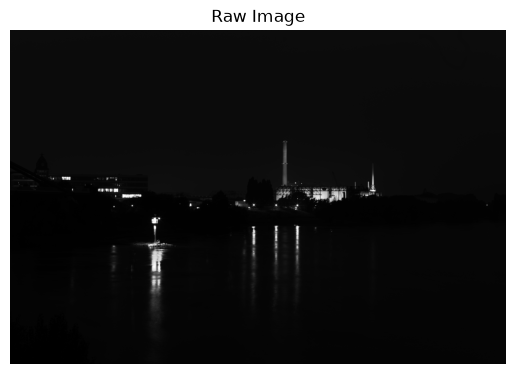

In [96]:
raw_data = Image.open("sample.tiff")
raw = np.array(raw_data).astype(np.double)
ShowImage(raw, "Raw Image", "gray")

green_mult = 1
red_mult = 2.10498046875
blue_mult = 1.25531005859375

wbscale_matrix = [[red_mult, green_mult], [green_mult, blue_mult]]

wb_scale = np.tile(
    wbscale_matrix,
    (raw.shape[0] // 2, raw.shape[1] // 2)
)

raw_wb = raw * wb_scale

# normalize 

raw_wb /= np.max(raw_wb)

#interpolation

colored = np.zeros((raw.shape[0]-2, raw.shape[1]-2, 3))

for x in range(1, raw.shape[0]-1):
    for y in range(1, raw.shape[1]-1):
        center = raw_wb[x, y]
        up = raw_wb[x - 1, y]
        down = raw_wb[x + 1, y]
        left = raw_wb[x, y - 1]
        right = raw_wb[x, y + 1]

        diagonals = (
            raw_wb[x - 1, y - 1] +
            raw_wb[x - 1, y + 1] +
            raw_wb[x + 1, y - 1] +
            raw_wb[x + 1, y + 1]
        ) / 4

        if x % 2 == 0 and y % 2 == 0:  # Red pixel
            red = center
            green = (up + down + left + right) / 4
            blue = diagonals

        elif x % 2 == 1 and y % 2 == 1:  # Blue pixel
            red = diagonals
            green = (up + down + left + right) / 4
            blue = center

        else:  # Green pixel
            green = center

            if x % 2 == 0:  # Green on a red row
                red = (left + right) / 2
                blue = (up + down) / 2
            else:  # Green on a blue row
                red = (up + down) / 2
                blue = (left + right) / 2

        colored[x - 1, y - 1] = [red, green, blue]


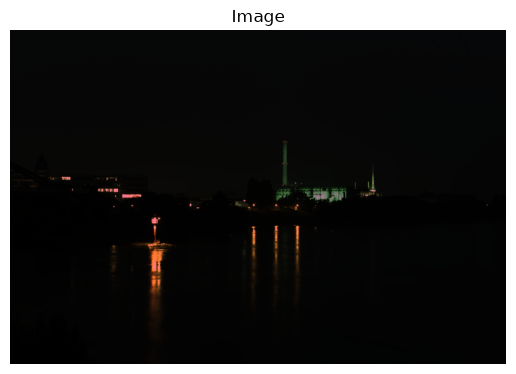

In [97]:
ShowImage(colored)

In [98]:
def MeanLuminance(image):
    return np.mean(
        0.2126 * image[:, :, 0] +
        0.7152 * image[:, :, 1] +
        0.0722 * image[:, :, 2]
    )

In [99]:

print(MeanLuminance(colored))

0.02427464454552913


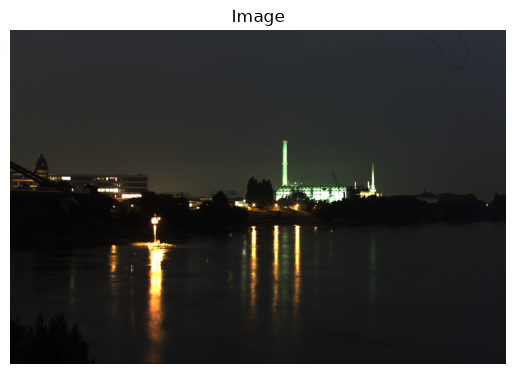

0.14312499115544644


In [109]:
# correct bightness
exposure = 6.5
colored_bc = np.copy(colored)
colored_bc *= exposure
colored_bc = np.clip(colored_bc, max=1, min=0)
ShowImage(colored_bc)
print(MeanLuminance(colored_bc))

In [110]:
def GammaCorrection(image, gamma):
    return np.power(image, gamma)
    

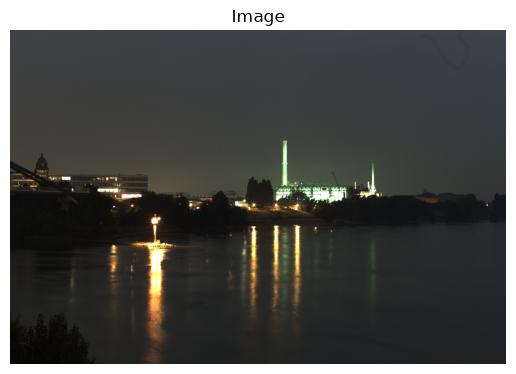

In [112]:
colored_gamma = GammaCorrection(colored_bc, 0.8)
ShowImage(colored_gamma)